# Дизайн эксперимента

*Тест анализируется постфактум на открытых данных. Гипотеза, метрики и критерий решения зафиксированы до просмотра результатов по группам.*  

**Изменение.** Первые ворота (gate) — точка, где игрок должен подождать или заплатить, чтобы играть дальше, — перенесены с 30-го уровня на 40-й. Контроль — `gate_30`, тест — `gate_40`.

**1. Продуктовая гипотеза.** Ворота прерывают игровую сессию. Если отодвинуть их дальше, игрок дольше играет без помех и сильнее вовлекается, тогда удержание пользователя может вырасти. Возможен и обратный эффект: ворота дают вынужденную паузу, игрок не успевает «наиграться» и возвращается позже. Без паузы игра может надоесть быстрее, и удержание упадёт. Поэтому направление эффекта заранее неизвестно.


**2. Единица рандомизации —** Пользователь (`userid`): игрок случайно попадает в одну из групп при установке игры и остаётся в ней.

**3. Метрики.**
- Основная — `retention_7` (игрок вернулся через 7 дней после установки). Недельное удержание ближе к долгосрочной ценности игрока, чем удержание первого дня. Кроме того, многие игроки в первый день не доходят до 30-го уровня, и изменение для них ещё не наступило.
- Вторичные — `retention_1` и `sum_gamerounds` (число сыгранных раундов за первые 14 дней). Они помогают интерпретировать результат, но решение по ним не принимается.
- Ограничение: в данных нет выручки, поэтому влияние на монетизацию (покупки на воротах) проверить нельзя.

**4. Статистические гипотезы** (для `retention_7`):

$H_0: p_{40} = p_{30}$ — перенос ворот **не влияет** на 7-дневное удержание;

$H_1: p_{40} \neq p_{30}$ — перенос ворот **влияет** на 7-дневное удержание.

Гипотеза двусторонняя: эффект может оказаться в любую сторону, и падение удержания нам так же важно заметить, как и рост.

**5. Уровень значимости.** $\alpha = 0.05$. Если перенос ворот на самом деле ни на что не влияет, разница между группами всё равно будет из-за случайности. $\alpha$ — допустимая вероятность принять такой шум за эффект (ошибка I рода) и принять решение на его основе: мы готовы ошибаться так не чаще, чем в 5% подобных тестов.

**Критерий решения.**
- `retention_7` в `gate_40` значимо выше — переносим ворота на 40-й уровень.
- Значимо ниже — оставляем на 30-м.
- Разница незначима — не меняем: доказательств пользы нет.

**План анализа.**
1. Проверка валидности: EDA (пропуски, дубли, выбросы) и SRM-проверка $\chi^2$-тестом на размеры групп.
2. Оценка эффекта: z-тест для двух долей и 95% доверительный интервал разницы; бутстрап как проверка без допущений о нормальности.
3. Анализ мощности: какой минимальный эффект (MDE) тест мог обнаружить.

# Загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

# папка для графиков (README ссылается на неё)
Path("../images").mkdir(exist_ok=True)

In [2]:
df = pd.read_csv("../data/cookie_cats.csv")
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


# EDA

## Типы и пропуски

In [3]:
df.info()
print()
print("Пропусков по колонкам:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB

Пропусков по колонкам:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


Пропусков нет.

## Дубли

In [4]:
print("Полных дублей строк:", df.duplicated().sum())
print("Повторяющихся userid:", df["userid"].duplicated().sum())

Полных дублей строк: 0
Повторяющихся userid: 0


## Размеры групп

In [5]:
group_sizes = pd.DataFrame({
    "игроков": df["version"].value_counts(),
    "доля": df["version"].value_counts(normalize=True).round(4),
})
group_sizes

,игроков,доля
version,,
gate_40,45489,0.5044
gate_30,44700,0.4956


## Раунды по группам

In [6]:
# описательные статистики числа раундов за 14 дней в разрезе групп
percentiles = [0.25, 0.5, 0.75, 0.9, 0.99]
df.groupby("version")["sum_gamerounds"].describe(percentiles=percentiles).round(1)

,count,mean,std,min,25%,50%,75%,90%,99%,max
version,,,,,,,,,,
gate_30,44700.0,52.5,256.7,0.0,5.0,17.0,50.0,135.0,493.0,49854.0
gate_40,45489.0,51.3,103.3,0.0,5.0,16.0,52.0,134.0,492.1,2640.0


Длинный правый хвост: медиана 16–17 раундов, среднее ~51. Std в `gate_30` сильно больше из-за одного игрока с 49 854 раундами.

## Игроки с 0 раундов

In [7]:
zero = df["sum_gamerounds"] == 0
print(f"Игроков с 0 раундов: {zero.sum()} ({zero.mean():.2%})")
# ориентир для интерпретации: кто сыграл меньше 30 раундов, вероятно, не дошёл до первых ворот
print(f"Игроков с < 30 раундов: {(df['sum_gamerounds'] < 30).mean():.1%}")
zero.groupby(df["version"]).agg(["sum", "mean"]).rename(columns={"sum": "игроков", "mean": "доля"})

Игроков с 0 раундов: 3994 (4.43%)
Игроков с < 30 раундов: 63.1%


,игроков,доля
version,,
gate_30,1937,0.043333
gate_40,2057,0.045220


Игроков с 0 раундов (4.4%) оставляю: рандомизация шла при установке, они часть аудитории теста.

## Выбросы

49 854 раунда за 14 дней — это ~3 500 в день, скорее бот или ошибка логов. Удаляю по правилу `sum_gamerounds > 10000` для обеих групп, дальше работаю с `df_clean`.

In [8]:
OUTLIER_THRESHOLD = 10_000

df_clean = df[df["sum_gamerounds"] <= OUTLIER_THRESHOLD].copy()
removed = df[df["sum_gamerounds"] > OUTLIER_THRESHOLD]

print(f"Удалено строк: {len(removed)}")
print(removed["version"].value_counts().to_string())
print(f"Осталось: {len(df_clean)}")
df_clean.groupby("version")["sum_gamerounds"].describe(percentiles=percentiles).round(1)

Удалено строк: 1
version
gate_30    1
Осталось: 90188


,count,mean,std,min,25%,50%,75%,90%,99%,max
version,,,,,,,,,,
gate_30,44699.0,51.3,102.1,0.0,5.0,17.0,50.0,135.0,493.0,2961.0
gate_40,45489.0,51.3,103.3,0.0,5.0,16.0,52.0,134.0,492.1,2640.0


Удалена одна строка, после этого группы по раундам почти одинаковые.

## Распределение раундов

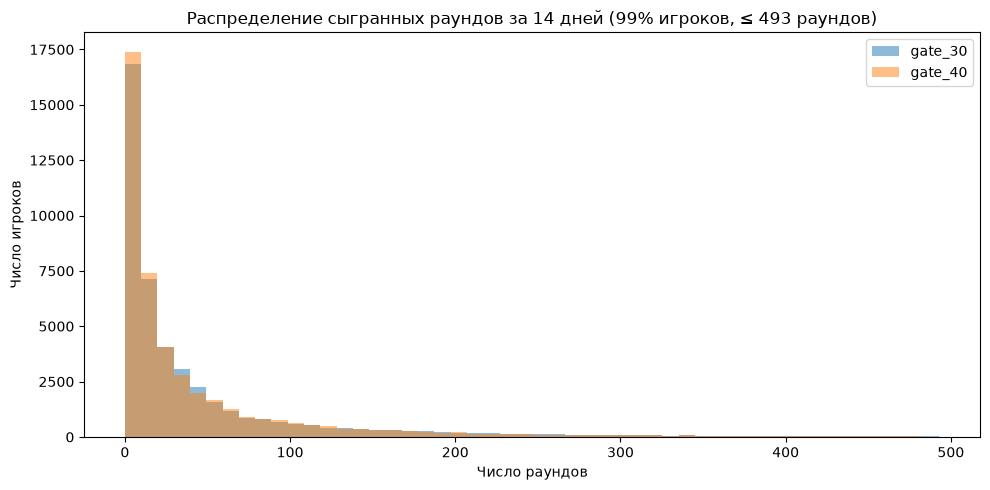

In [9]:
cap = df_clean["sum_gamerounds"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 5))
for version, group in df_clean.groupby("version"):
    rounds = group.loc[group["sum_gamerounds"] <= cap, "sum_gamerounds"]
    ax.hist(rounds, bins=50, alpha=0.5, label=version)

ax.set_title(f"Распределение сыгранных раундов за 14 дней (99% игроков, ≤ {cap:.0f} раундов)")
ax.set_xlabel("Число раундов")
ax.set_ylabel("Число игроков")
ax.legend()
plt.tight_layout()
plt.savefig("../images/rounds_distribution.png", dpi=150)
plt.show()

Хвост выше 99-го перцентиля (493 раунда) отрезан только на графике. Группы почти не отличаются.

# SRM

Проверяю, что группы разбиты 50/50 без перекоса. Если перекос есть (SRM), скорее всего что-то сломано в сплите или логировании, и результатам теста доверять нельзя.

$$\chi^2 = \sum_i \frac{(O_i - E_i)^2}{E_i}, \quad E_i = N/2$$

Порог для SRM берут строже обычного — $p < 0.001$, чтобы не ловить ложные тревоги.

In [10]:
def srm_check(data, label):
    observed = data["version"].value_counts().sort_index()  # gate_30, gate_40
    expected = np.full(2, len(data) / 2)                    # план 50/50
    chi2, p = stats.chisquare(f_obs=observed.values, f_exp=expected)
    print(f"{label}: gate_30={observed['gate_30']}, gate_40={observed['gate_40']}, "
          f"ожидаемо по {expected[0]:.1f}; chi2={chi2:.3f}, p-value={p:.4f}")
    return chi2, p

SRM_ALPHA = 0.001
chi2_srm, p_srm = srm_check(df, "Все игроки")
srm_check(df_clean, "df_clean   ")
print("SRM обнаружен" if p_srm < SRM_ALPHA else "SRM не обнаружен (p >= 0.001)")

Все игроки: gate_30=44700, gate_40=45489, ожидаемо по 45094.5; chi2=6.902, p-value=0.0086
df_clean   : gate_30=44699, gate_40=45489, ожидаемо по 45094.0; chi2=6.920, p-value=0.0085
SRM не обнаружен (p >= 0.001)


$\chi^2 = 6.90$, p = 0.0086 > 0.001 — SRM нет.

# z-тест для двух долей

Retention — доля вернувшихся, в группах по ~45 тыс. игроков, так что нормальное приближение работает.

z-статистика (pooled SE, при $H_0$ доли равны):

$$\hat p = \frac{x_{30} + x_{40}}{n_{30} + n_{40}}, \quad SE_{pooled} = \sqrt{\hat p (1 - \hat p)\left(\frac{1}{n_{30}} + \frac{1}{n_{40}}\right)}, \quad z = \frac{\hat p_{40} - \hat p_{30}}{SE_{pooled}}$$

95% ДИ разницы (unpooled SE):

$$SE = \sqrt{\frac{\hat p_{30}(1 - \hat p_{30})}{n_{30}} + \frac{\hat p_{40}(1 - \hat p_{40})}{n_{40}}}, \quad (\hat p_{40} - \hat p_{30}) \pm 1.96 \cdot SE$$

In [11]:
ALPHA = 0.05

def two_prop_ztest(data, metric, alpha=ALPHA):
    """z-тест для разницы долей gate_40 − gate_30, расчёт вручную."""
    g = data.groupby("version")[metric].agg(["sum", "count"])
    x30, n30 = g.loc["gate_30"]
    x40, n40 = g.loc["gate_40"]
    p30, p40 = x30 / n30, x40 / n40
    diff = p40 - p30

    # pooled SE — для z-статистики (в предположении H0: p40 = p30)
    p_pool = (x30 + x40) / (n30 + n40)
    se_pooled = np.sqrt(p_pool * (1 - p_pool) * (1 / n30 + 1 / n40))
    z = diff / se_pooled
    p_value = 2 * stats.norm.sf(abs(z))

    # unpooled SE — для доверительного интервала разницы
    se_unpooled = np.sqrt(p30 * (1 - p30) / n30 + p40 * (1 - p40) / n40)
    z_crit = stats.norm.ppf(1 - alpha / 2)
    ci_low, ci_high = diff - z_crit * se_unpooled, diff + z_crit * se_unpooled

    return {
        "метрика": metric, "p_30": p30, "p_40": p40, "diff": diff,
        "rel_diff": diff / p30, "z": z, "p_value": p_value,
        "ci_low": ci_low, "ci_high": ci_high,
        "x": np.array([x40, x30]), "n": np.array([n40, n30]),
    }

results = {m: two_prop_ztest(df_clean, m) for m in ["retention_7", "retention_1"]}

Сверка с `statsmodels`:

In [12]:
for metric, r in results.items():
    # порядок групп [gate_40, gate_30] -> z для разницы gate_40 − gate_30
    z_sm, p_sm = proportions_ztest(count=r["x"], nobs=r["n"], alternative="two-sided")
    print(f"{metric}: вручную z={r['z']:.4f}, p={r['p_value']:.5f} | "
          f"statsmodels z={z_sm:.4f}, p={p_sm:.5f} | совпадает: "
          f"{np.isclose(r['z'], z_sm) and np.isclose(r['p_value'], p_sm)}")

retention_7: вручную z=-3.1574, p=0.00159 | statsmodels z=-3.1574, p=0.00159 | совпадает: True
retention_1: вручную z=-1.7871, p=0.07392 | statsmodels z=-1.7871, p=0.07392 | совпадает: True


In [13]:
summary = pd.DataFrame([
    {
        "метрика": r["метрика"],
        "gate_30, %": r["p_30"] * 100,
        "gate_40, %": r["p_40"] * 100,
        "разница, п.п.": r["diff"] * 100,
        "отн. разница, %": r["rel_diff"] * 100,
        "z": r["z"],
        "p-value": r["p_value"],
        "95% ДИ, п.п.": f"[{r['ci_low'] * 100:.2f}; {r['ci_high'] * 100:.2f}]",
    }
    for r in results.values()
]).set_index("метрика")

summary.round({"gate_30, %": 2, "gate_40, %": 2, "разница, п.п.": 2,
               "отн. разница, %": 2, "z": 2, "p-value": 4})

,"gate_30, %","gate_40, %","разница, п.п.","отн. разница, %",z,p-value,"95% ДИ, п.п."
метрика,,,,,,,
retention_7,19.02,18.20,-0.82,-4.30,-3.16,0.0016,[-1.33; -0.31]
retention_1,44.82,44.23,-0.59,-1.32,-1.79,0.0739,[-1.24; 0.06]


`retention_7`: 19.02% → 18.20%, разница −0.82 п.п. (−4.3%), p = 0.0016, 95% ДИ [−1.33; −0.31] п.п. Если бы эффекта не было, такая разница случайно получалась бы примерно в 0.16% случаев. Весь интервал ниже нуля — в `gate_40` удержание хуже.

`retention_1`: −0.59 п.п., p = 0.074, ДИ [−1.24; 0.06] п.п. — незначимо.

Решение принимаю только по `retention_7`, это основная метрика из дизайна. Чем больше метрик проверяешь, тем выше шанс случайно найти «значимую».

# Бутстрап

10 000 раз пересобираю каждую группу из её же игроков с возвращением и считаю разницу retention. По этим разницам видно, насколько она может «гулять»; 95% ДИ — 2.5-й и 97.5-й перцентили. Нормальность тут не нужна, так что это проверка z-теста.

In [14]:
N_BOOT = 10_000
CHUNK = 1_000           # ресэмплов за итерацию — ограничивает расход памяти
rng = np.random.default_rng(42)
metrics = ["retention_7", "retention_1"]

def bootstrap_means(values, n_boot=N_BOOT, chunk=CHUNK):
    """Средние по n_boot ресэмплам с возвращением; values — матрица (n_игроков, n_метрик)."""
    n = len(values)
    out = np.empty((n_boot, values.shape[1]))
    for start in range(0, n_boot, chunk):
        size = min(chunk, n_boot - start)
        idx = rng.integers(0, n, size=(size, n), dtype=np.int32)  # индексы игроков
        for j in range(values.shape[1]):
            out[start:start + size, j] = values[idx, j].mean(axis=1)
    return out

boot = {
    v: bootstrap_means(df_clean.loc[df_clean["version"] == v, metrics].to_numpy(dtype=np.int8))
    for v in ["gate_30", "gate_40"]
}
boot_diff = pd.DataFrame(boot["gate_40"] - boot["gate_30"], columns=metrics)  # gate_40 − gate_30

boot_ci = {}
rows = []
for m in metrics:
    low, high = np.percentile(boot_diff[m], [2.5, 97.5])
    boot_ci[m] = (low, high)
    r = results[m]
    rows.append({
        "метрика": m,
        "разница, п.п.": r["diff"] * 100,
        "ДИ бутстрап, п.п.": f"[{low * 100:.2f}; {high * 100:.2f}]",
        "ДИ z-тест, п.п.": f"[{r['ci_low'] * 100:.2f}; {r['ci_high'] * 100:.2f}]",
        "доля ресэмплов с разницей > 0": (boot_diff[m] > 0).mean(),
    })
pd.DataFrame(rows).set_index("метрика").round(4)

,"разница, п.п.","ДИ бутстрап, п.п.","ДИ z-тест, п.п.",доля ресэмплов с разницей > 0
метрика,,,,
retention_7,-0.8183,[-1.32; -0.32],[-1.33; -0.31],0.0004
retention_1,-0.5915,[-1.27; 0.05],[-1.24; 0.06],0.0376


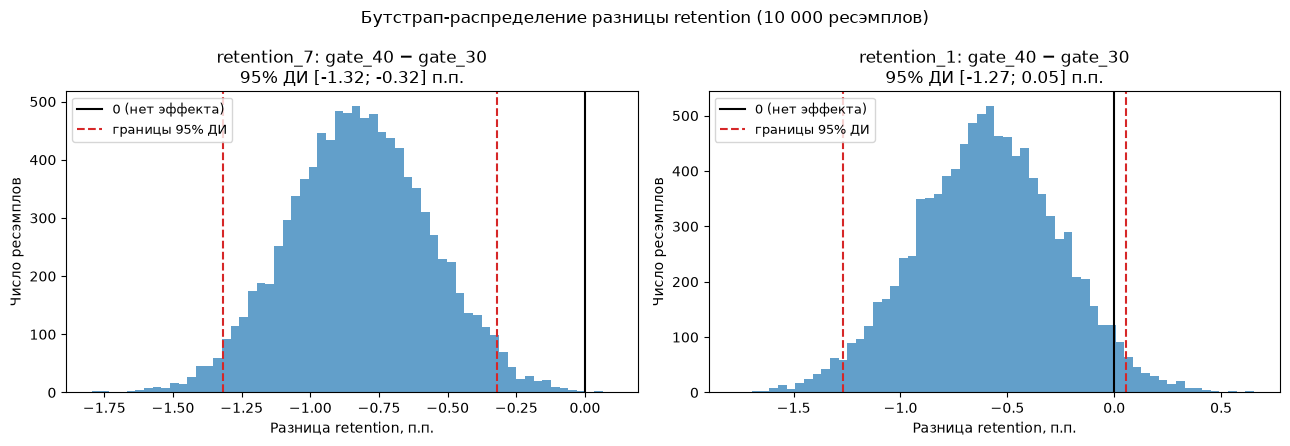

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, m in zip(axes, metrics):
    low, high = boot_ci[m]
    ax.hist(boot_diff[m] * 100, bins=60, color="tab:blue", alpha=0.7)
    ax.axvline(0, color="black", linewidth=1.5, label="0 (нет эффекта)")
    ax.axvline(low * 100, color="tab:red", linestyle="--", label="границы 95% ДИ")
    ax.axvline(high * 100, color="tab:red", linestyle="--")
    ax.set_title(f"{m}: gate_40 − gate_30\n95% ДИ [{low * 100:.2f}; {high * 100:.2f}] п.п.")
    ax.set_xlabel("Разница retention, п.п.")
    ax.set_ylabel("Число ресэмплов")
    ax.legend(loc="upper left", fontsize=9)
fig.suptitle(f"Бутстрап-распределение разницы retention ({N_BOOT:,} ресэмплов)".replace(",", " "))
plt.tight_layout()
plt.savefig("../images/bootstrap_retention_diff.png", dpi=150)
plt.show()

Интервалы почти совпадают с z-тестом: `retention_7` [−1.32; −0.32] п.п., `retention_1` [−1.27; 0.05] п.п. Выводы те же.

# Мощность и MDE

Ошибка I рода — решить, что перенос ворот влияет на удержание, когда на самом деле нет ($\alpha = 0.05$). Ошибка II рода — не заметить эффект, который есть ($\beta$). Мощность $1 - \beta$ — шанс эффект заметить, беру 0.8.

MDE — минимальный эффект, который тест с такими выборками поймает с мощностью 0.8:

$$MDE \approx (z_{1-\alpha/2} + z_{1-\beta})\sqrt{p_{30}(1 - p_{30})\left(\frac{1}{n_{30}} + \frac{1}{n_{40}}\right)}$$

Наблюдаемую (post-hoc) мощность не считаю: она однозначно выражается через p-value и ничего нового не даёт.

In [16]:
POWER = 0.8
r7 = results["retention_7"]
p30 = r7["p_30"]
n40, n30 = r7["n"]

# 1) по формуле
z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_beta = stats.norm.ppf(POWER)
mde_formula = (z_alpha + z_beta) * np.sqrt(p30 * (1 - p30) * (1 / n30 + 1 / n40))

# 2) statsmodels: минимальный Cohen's h при фактических размерах групп
h_min = NormalIndPower().solve_power(
    effect_size=None, nobs1=n40, ratio=n30 / n40, alpha=ALPHA, power=POWER, alternative="two-sided"
)
# переводим h обратно в доли: падение и рост относительно p30
phi30 = 2 * np.arcsin(np.sqrt(p30))
p_down = np.sin((phi30 - h_min) / 2) ** 2
p_up = np.sin((phi30 + h_min) / 2) ** 2
# проверка: proportion_effectsize возвращает тот же h
assert np.isclose(proportion_effectsize(p_up, p30), h_min)

print(f"Контрольная доля retention_7: {p30:.4f}; n_30 = {n30}, n_40 = {n40}")
print(f"MDE по формуле:        {mde_formula * 100:.2f} п.п. ({mde_formula / p30:.1%} от контроля)")
print(f"Cohen's h (statsmodels): {h_min:.4f}")
print(f"MDE через h: рост до {p_up:.4f} (+{(p_up - p30) * 100:.2f} п.п.), "
      f"падение до {p_down:.4f} ({(p_down - p30) * 100:.2f} п.п.)")
print(f"Наблюдаемая разница:  {r7['diff'] * 100:.2f} п.п.")

Контрольная доля retention_7: 0.1902; n_30 = 44699, n_40 = 45489
MDE по формуле:        0.73 п.п. (3.9% от контроля)
Cohen's h (statsmodels): 0.0187
MDE через h: рост до 0.1976 (+0.74 п.п.), падение до 0.1829 (-0.73 п.п.)
Наблюдаемая разница:  -0.82 п.п.


MDE ≈ 0.73 п.п. (3.9% от 19.02%). Наблюдаемый эффект −0.82 п.п. больше, так что чувствительности теста хватило. Эффекты меньше ~0.7 п.п. он бы, скорее всего, не увидел.

# Итог

**`gate_40` не катим, ворота остаются на 30-м уровне.** `retention_7` в `gate_40` значимо ниже: −0.82 п.п., p = 0.0016, ДИ [−1.33; −0.31] п.п., бутстрап даёт то же. `retention_1` тоже ниже, но незначимо.

Ограничения:
- дизайн восстановлен постфактум;
- SRM прошёл по порогу 0.001, но p = 0.0086 — перекос групп стоило бы сверить с логами;
- нет данных о выручке, а ворота — это ещё и монетизация;
- ~63% игроков сыграли меньше 30 раундов и, скорее всего, до ворот не дошли — они разбавляют эффект;
- retention только на 1-й и 7-й день;
- нет разрезов (платформа, страна и т.п.).